In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder, PolynomialFeatures
from sklearn import metrics

# Create the dataset directly instead of reading a CSV file
df = pd.DataFrame({
    "Position": ["Analyst", "Analyst", "Developer", "Developer",
                 "Manager", "Manager", "Director", "Director",
                 "CEO", "CEO"],
    "Level": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10],
    "Salary": [25000, 30000, 40000, 45000, 55000,
               60000, 75000, 85000, 100000, 120000]
})

# Display the dataset
print(df)

    Position  Level  Salary
0    Analyst      1   25000
1    Analyst      2   30000
2  Developer      3   40000
3  Developer      4   45000
4    Manager      5   55000
5    Manager      6   60000
6   Director      7   75000
7   Director      8   85000
8        CEO      9  100000
9        CEO     10  120000


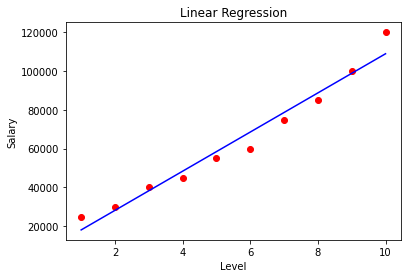

RMSE is: 5493.798156268411


In [2]:
# Select Level as input and Salary as output
x = df[["Level"]].values
y = df["Salary"].values

# Train the Linear Regression model
lin_reg = LinearRegression().fit(x, y)

# Predict the salary
pred_y = lin_reg.predict(x)

# Plot actual and predicted values
plt.scatter(x, y, color='red')
plt.plot(x, pred_y, color='blue')
plt.title('Linear Regression')
plt.xlabel('Level')
plt.ylabel('Salary')
plt.show()

# Calculate RMSE
print("RMSE is:", np.sqrt(metrics.mean_squared_error(y, pred_y)))

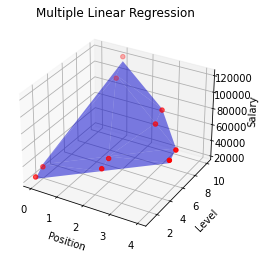

RMSE is: 3120.4249378616173


In [4]:
# Convert Position names into numbers
df["Position"] =  LabelEncoder().fit_transform(df["Position"])

# Select Position and Level as inputs
x_multi = df[["Position", "Level"]].values
y_multi = df["Salary"].values

# Train the Multiple Linear Regression model
model = LinearRegression().fit(x_multi, y_multi)

# Predict the salary
predicted_y = model.predict(x_multi)

# Plot the results in 3D
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(x_multi[:, 0], x_multi[:, 1], y_multi, color='red')
ax.plot_trisurf(x_multi[:, 0], x_multi[:, 1], predicted_y,
                alpha=0.5, color='blue')

ax.set_title("Multiple Linear Regression")
ax.set_xlabel("Position")
ax.set_ylabel("Level")
ax.set_zlabel("Salary")
plt.show()

# Calculate RMSE
print("RMSE is:", np.sqrt(metrics.mean_squared_error(y_multi, predicted_y)))